# Laboratório — Redes Neurais Convolucionais (CNN) — Parte I

# Setup

In [23]:
# Importar as bibliotecas utilizadas no notebook

import os
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Definir sementes para tornar os experimentos mais reproduzíveis

np.random.seed(42)
tf.random.set_seed(42)


# 1. Carregamento dos Dados

In [24]:
# Carregar o Fashion-MNIST
#
# Se o arquivo utilizado nos laboratórios anteriores estiver disponível,
# ele será utilizado. Caso contrário, o próprio Keras fará o download do dataset.

if os.path.exists("fashion_mnist.npz"):
    dados = np.load("fashion_mnist.npz")

    X_train = dados["X_train"]
    y_train = dados["y_train"]
    X_test = dados["X_test"]
    y_test = dados["y_test"]

    origem = "arquivo local fashion_mnist.npz"
else:
    (X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()
    origem = "keras.datasets.fashion_mnist"

nomes_classes = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print(f"Origem dos dados: {origem}")
print(f"Treinamento: {X_train.shape}")
print(f"Teste: {X_test.shape}")
print(f"Quantidade de classes: {len(np.unique(y_train))}")
print(f"Tipo dos pixels: {X_train.dtype}")
print(f"Intervalo original dos pixels: {X_train.min()} a {X_train.max()}")


Origem dos dados: arquivo local fashion_mnist.npz
Treinamento: (60000, 28, 28)
Teste: (10000, 28, 28)
Quantidade de classes: 10
Tipo dos pixels: uint8
Intervalo original dos pixels: 0 a 255


## Perguntas

1. Qual é a dimensão de cada imagem e quantas classes existem no Fashion-MNIST?  
2. No laboratório anterior com MLP, uma imagem 28 × 28 podia ser transformada em 784 valores. Por que, em uma CNN, é importante preservar a organização espacial 28 × 28?  
3. As imagens do Fashion-MNIST estão em escala de cinza. Quantos canais possui cada imagem? Quantos canais teria uma imagem RGB?


# 2. A Imagem como Matriz

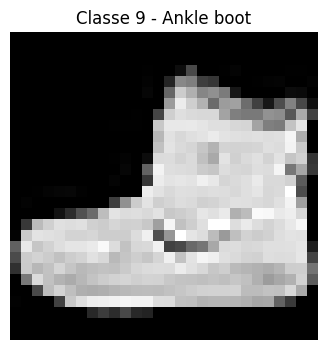

Shape da imagem: (28, 28)
Valor mínimo: 0
Valor máximo: 255

Região 5 × 5 da imagem:
[[  0   0   0 193 228]
 [  3   0  12 219 220]
 [  6   0  99 244 222]
 [  0   0  55 236 228]
 [  0   0 237 226 217]]


In [25]:
# Selecionar e visualizar uma imagem do conjunto de treinamento

indice = 0
imagem_original = X_train[indice]

plt.figure(figsize=(4, 4))
plt.imshow(imagem_original, cmap="gray")
plt.title(f"Classe {y_train[indice]} - {nomes_classes[y_train[indice]]}")
plt.axis("off")
plt.show()

print(f"Shape da imagem: {imagem_original.shape}")
print(f"Valor mínimo: {imagem_original.min()}")
print(f"Valor máximo: {imagem_original.max()}")

# Observar numericamente uma pequena região da imagem

regiao_5x5 = imagem_original[10:15, 10:15]

print("\nRegião 5 × 5 da imagem:")
print(regiao_5x5)


## Perguntas

4. O que representa cada número da matriz 28 × 28 mostrada acima?  
5. Se um filtro 3 × 3 for aplicado a essa imagem em escala de cinza, quantos pixels da imagem são analisados em cada posição do filtro?


# 3. Preparação da Entrada para a CNN

In [26]:
# Normalizar os pixels para o intervalo entre 0 e 1

X_train_cnn = X_train.astype("float32") / 255.0
X_test_cnn = X_test.astype("float32") / 255.0

# Adicionar explicitamente a dimensão correspondente ao canal
#
# Antes:  (quantidade, altura, largura)
# Depois: (quantidade, altura, largura, canais)

X_train_cnn = np.expand_dims(X_train_cnn, axis=-1)
X_test_cnn = np.expand_dims(X_test_cnn, axis=-1)

print(f"Shape de X_train original: {X_train.shape}")
print(f"Shape de X_train para CNN: {X_train_cnn.shape}")
print(f"Shape de uma imagem:       {X_train_cnn[0].shape}")
print(f"Intervalo normalizado:     {X_train_cnn.min():.1f} a {X_train_cnn.max():.1f}")


Shape de X_train original: (60000, 28, 28)
Shape de X_train para CNN: (60000, 28, 28, 1)
Shape de uma imagem:       (28, 28, 1)
Intervalo normalizado:     0.0 a 1.0


## Perguntas

6. Por que foi necessário adicionar uma nova dimensão ao final das imagens com `np.expand_dims(..., axis=-1)`?  
7. O que representa cada dimensão do formato `28 × 28 × 1`?  
8. Por que os valores dos pixels foram divididos por 255?


# 4. Kernel: uma Operação Local

Um filtro (*kernel*) é uma pequena matriz de pesos aplicada sobre regiões locais da imagem.

Para uma imagem com **um canal**, em uma determinada posição podemos representar o cálculo por:

\[
z = \sum_{u,v} x_{u,v}w_{u,v} + b
\]

e, após a função de ativação:

\[
a = f(z)
\]

Nesta primeira demonstração usaremos **pesos definidos manualmente apenas para tornar a operação visível**. Em uma `Conv2D` real, esses pesos e o bias são parâmetros treináveis.


In [27]:
# Selecionar uma região 3 × 3 da imagem normalizada

imagem = X_train_cnn[indice, :, :, 0]

linha = 12
coluna = 12

regiao = imagem[linha:linha + 3, coluna:coluna + 3]

# Kernel definido manualmente apenas para demonstrar o cálculo
# Os mesmos pesos serão reutilizados quando o filtro se deslocar pela imagem.

kernel_demo = np.array([
    [ 1.0,  0.0, -1.0],
    [ 1.0,  0.0, -1.0],
    [ 1.0,  0.0, -1.0]
], dtype="float32")

bias_demo = 0.0

produto_elemento_a_elemento = regiao * kernel_demo
z = np.sum(produto_elemento_a_elemento) + bias_demo
a = max(0.0, z)  # ReLU

print("Região 3 × 3 da imagem:")
print(np.round(regiao, 3))

print("\nKernel 3 × 3:")
print(kernel_demo)

print("\nProduto elemento a elemento:")
print(np.round(produto_elemento_a_elemento, 3))

print(f"\nZ = soma dos produtos + bias = {z:.4f}")
print(f"a = ReLU(Z) = {a:.4f}")


Região 3 × 3 da imagem:
[[0.388 0.957 0.871]
 [0.216 0.925 0.894]
 [0.929 0.886 0.851]]

Kernel 3 × 3:
[[ 1.  0. -1.]
 [ 1.  0. -1.]
 [ 1.  0. -1.]]

Produto elemento a elemento:
[[ 0.388  0.    -0.871]
 [ 0.216  0.    -0.894]
 [ 0.929  0.    -0.851]]

Z = soma dos produtos + bias = -1.0824
a = ReLU(Z) = 0.0000


## Perguntas

9. Qual é o papel dos valores armazenados no kernel durante esse cálculo?  
10. Qual é a diferença entre o valor `Z` e o valor de ativação `a`?  
11. Quando esse mesmo filtro for deslocado para outra região da imagem, quais valores do cálculo são reutilizados?


# 5. Do Deslocamento do Kernel ao Mapa de Características

Shape da imagem de entrada: (28, 28)
Shape do mapa gerado:       (26, 26)


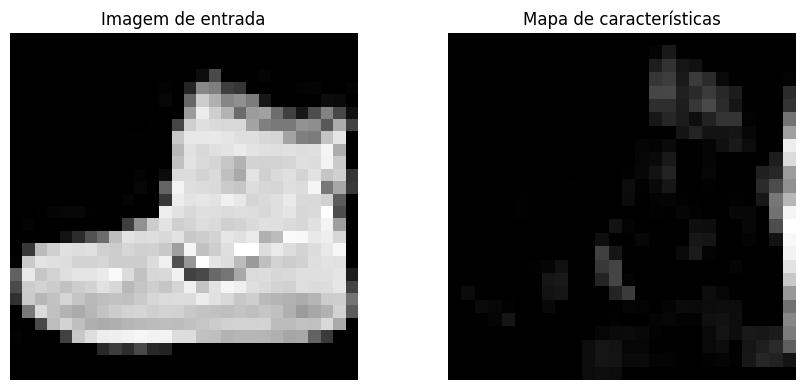

In [28]:
# Aplicar o mesmo kernel sobre todas as regiões 3 × 3 possíveis da imagem.
#
# O objetivo desta implementação explícita é mostrar que:
# cada posição do filtro produz um valor da nova matriz.

altura_saida = imagem.shape[0] - kernel_demo.shape[0] + 1
largura_saida = imagem.shape[1] - kernel_demo.shape[1] + 1

mapa_demo = np.zeros((altura_saida, largura_saida), dtype="float32")

for i in range(altura_saida):
    for j in range(largura_saida):
        regiao_atual = imagem[i:i + 3, j:j + 3]
        z_atual = np.sum(regiao_atual * kernel_demo) + bias_demo
        mapa_demo[i, j] = max(0.0, z_atual)

print(f"Shape da imagem de entrada: {imagem.shape}")
print(f"Shape do mapa gerado:       {mapa_demo.shape}")

plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)
plt.imshow(imagem, cmap="gray")
plt.title("Imagem de entrada")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mapa_demo, cmap="gray")
plt.title("Mapa de características")
plt.axis("off")

plt.tight_layout()
plt.show()


## Perguntas

12. Por que cada posição do filtro produz apenas **um valor** no mapa de características?  
13. Por que reutilizar os mesmos pesos do filtro em diferentes regiões permite procurar o mesmo tipo de padrão em diferentes posições da imagem?


# 6. Primeira Camada Convolucional: Vários Filtros

In [29]:
# Construir apenas a primeira camada convolucional.
#
# Nesta Parte I queremos isolar o funcionamento da primeira convolução.
# Não há ainda pooling, Flatten, Dense ou uma segunda camada convolucional.

modelo_conv1 = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(
        filters=4,
        kernel_size=(3, 3),
        activation="relu",
        name="conv1"
    )
])

modelo_conv1.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 26, 26, 4)      │            40 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40 (160.00 B)

 Trainable params: 40 (160.00 B)

 Non-trainable params: 0 (0.00 B)

## Perguntas

14. O que significa `filters=4` nessa camada?  
15. O que significa `kernel_size=(3, 3)`?  
16. Por que a saída da camada possui profundidade 4, mesmo que a entrada tenha apenas 1 canal?  
17. Classifique os itens a seguir como **parâmetros treináveis** ou **hiperparâmetros de arquitetura**: pesos dos kernels, biases, quantidade de filtros, tamanho do kernel e função de ativação.


# 7. Pesos, Biases e Parâmetros Treináveis

In [30]:
# Inspecionar os parâmetros da primeira camada convolucional
#
# O TensorFlow armazena os kernels de uma Conv2D no formato:
# (altura_kernel, largura_kernel, canais_entrada, quantidade_filtros)

conv1 = modelo_conv1.get_layer("conv1")
pesos_conv1, biases_conv1 = conv1.get_weights()

print(f"Shape do conjunto de kernels: {pesos_conv1.shape}")
print(f"Shape dos biases:             {biases_conv1.shape}")
print(f"Parâmetros treináveis:        {conv1.count_params()}")

# Cálculo manual da quantidade de parâmetros
#
# Cada filtro:
# 3 × 3 × 1 pesos + 1 bias
#
# Como existem 4 filtros:

parametros_por_filtro = (3 * 3 * 1) + 1
parametros_totais = parametros_por_filtro * 4

print(f"\nParâmetros por filtro: {parametros_por_filtro}")
print(f"Parâmetros totais:     {parametros_totais}")


Shape do conjunto de kernels: (3, 3, 1, 4)
Shape dos biases:             (4,)
Parâmetros treináveis:        40

Parâmetros por filtro: 10
Parâmetros totais:     40


## Perguntas

18. Como interpretar o shape `(3, 3, 1, 4)` dos kernels da camada?  
19. Por que existem exatamente 4 biases?  
20. Refaça manualmente o cálculo da quantidade de parâmetros treináveis e confirme o total apresentado pelo TensorFlow.  
21. Por que a quantidade de parâmetros dessa camada depende do tamanho do kernel, da quantidade de canais de entrada e da quantidade de filtros, mas não diretamente do tamanho completo `28 × 28` da imagem?


# 8. Os Mapas de Características Produzidos pelos Filtros

Shape da entrada: (1, 28, 28, 1)
Shape da saída:   (26, 26, 4)
Quantidade de mapas gerados: 4


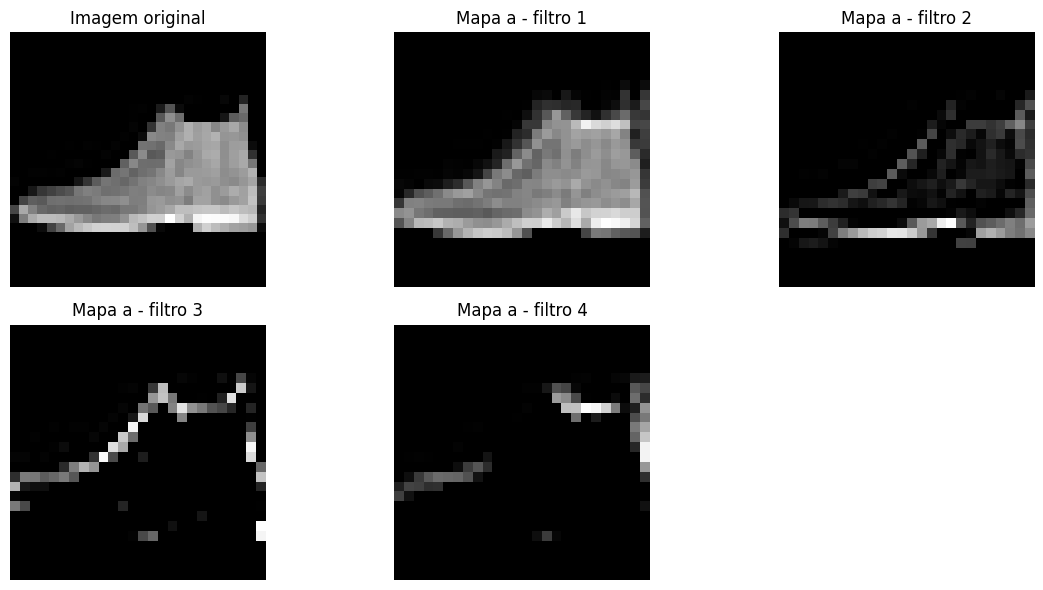

In [31]:
# Aplicar a primeira camada convolucional a uma única imagem
#
# Como a camada ainda não foi treinada, seus pesos estão apenas inicializados.
# O objetivo aqui é observar a relação:
#
# 4 filtros -> 4 mapas de características

imagem_teste = X_test_cnn[0:1]

mapas_conv1 = modelo_conv1.predict(imagem_teste, verbose=0)[0]

print(f"Shape da entrada: {imagem_teste.shape}")
print(f"Shape da saída:   {mapas_conv1.shape}")
print(f"Quantidade de mapas gerados: {mapas_conv1.shape[-1]}")

plt.figure(figsize=(12, 6))

plt.subplot(2, 3, 1)
plt.imshow(imagem_teste[0, :, :, 0], cmap="gray")
plt.title("Imagem original")
plt.axis("off")

for i in range(4):
    plt.subplot(2, 3, i + 2)
    plt.imshow(mapas_conv1[:, :, i], cmap="gray")
    plt.title(f"Mapa a - filtro {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


## Perguntas

22. Todos os filtros receberam exatamente a mesma imagem. Por que os quatro mapas produzidos são diferentes?  
23. Explique a relação entre as afirmações **“cada filtro possui pesos próprios”** e **“cada filtro produz seu próprio mapa de características”**.


# 9. Primeira Camada com Vários Canais de Entrada

Até aqui, a entrada possuía apenas um canal.

Em uma imagem RGB, a entrada teria três canais. Nesse caso, um filtro 3 × 3 precisa possuir uma matriz 3 × 3 para **cada canal da entrada**.

Portanto, um filtro teria dimensão:

\[
3 \times 3 \times 3
\]

Os resultados obtidos nos três canais são combinados, juntamente com o bias do filtro, para formar um único valor \(Z\).

Para observar apenas a estrutura, criaremos abaixo uma entrada com três canais repetindo a imagem em escala de cinza. **Isso não transforma a imagem em uma fotografia RGB real**; serve somente para reproduzir a estrutura `altura × largura × 3`.


In [32]:
# Criar uma entrada com três canais apenas para observar a estrutura

imagem_1_canal = X_test_cnn[0:1]
imagem_3_canais = np.repeat(imagem_1_canal, repeats=3, axis=-1)

print(f"Entrada com 1 canal:  {imagem_1_canal.shape}")
print(f"Entrada com 3 canais: {imagem_3_canais.shape}")

# Criar uma primeira camada Conv2D para uma entrada com 3 canais

modelo_rgb = keras.Sequential([
    layers.Input(shape=(28, 28, 3)),

    layers.Conv2D(
        filters=4,
        kernel_size=(3, 3),
        activation="relu",
        name="conv_rgb"
    )
])

conv_rgb = modelo_rgb.get_layer("conv_rgb")
pesos_rgb, biases_rgb = conv_rgb.get_weights()

print(f"\nShape do conjunto de kernels: {pesos_rgb.shape}")
print(f"Shape dos biases:             {biases_rgb.shape}")
print(f"Parâmetros treináveis:        {conv_rgb.count_params()}")

parametros_rgb = ((3 * 3 * 3) + 1) * 4
print(f"Cálculo manual:               {parametros_rgb}")


Entrada com 1 canal:  (1, 28, 28, 1)
Entrada com 3 canais: (1, 28, 28, 3)

Shape do conjunto de kernels: (3, 3, 3, 4)
Shape dos biases:             (4,)
Parâmetros treináveis:        112
Cálculo manual:               112


## Perguntas

24. Como interpretar o shape `(3, 3, 3, 4)` dos kernels?  
25. Quantas matrizes 3 × 3 existem dentro de **um único filtro** dessa camada? Por quê?  
26. Por que a saída continua tendo profundidade 4, e não profundidade 3?  
27. Calcule manualmente a quantidade de parâmetros treináveis dessa camada e explique por que ela possui mais parâmetros que a camada equivalente com apenas um canal de entrada.


# 10. Como um Filtro Combina Vários Canais

In [33]:
# Verificar explicitamente o cálculo de uma única posição
# para o primeiro filtro da camada com 3 canais.

linha = 10
coluna = 10
filtro = 0

regiao_rgb = imagem_3_canais[0, linha:linha + 3, coluna:coluna + 3, :]

contribuicao_canal_0 = np.sum(regiao_rgb[:, :, 0] * pesos_rgb[:, :, 0, filtro])
contribuicao_canal_1 = np.sum(regiao_rgb[:, :, 1] * pesos_rgb[:, :, 1, filtro])
contribuicao_canal_2 = np.sum(regiao_rgb[:, :, 2] * pesos_rgb[:, :, 2, filtro])

z_manual = (
    contribuicao_canal_0
    + contribuicao_canal_1
    + contribuicao_canal_2
    + biases_rgb[filtro]
)

a_manual = max(0.0, z_manual)

# Calcular a saída da camada com o TensorFlow para comparar

saida_rgb = modelo_rgb(imagem_3_canais, training=False).numpy()
a_tensorflow = saida_rgb[0, linha, coluna, filtro]

print(f"Contribuição do canal 1: {contribuicao_canal_0:.6f}")
print(f"Contribuição do canal 2: {contribuicao_canal_1:.6f}")
print(f"Contribuição do canal 3: {contribuicao_canal_2:.6f}")
print(f"Bias do filtro:          {biases_rgb[filtro]:.6f}")

print(f"\nZ calculado manualmente:       {z_manual:.6f}")
print(f"a = ReLU(Z) manual:             {a_manual:.6f}")
print(f"Saída calculada pelo TensorFlow: {a_tensorflow:.6f}")


Contribuição do canal 1: 0.001370
Contribuição do canal 2: 0.000610
Contribuição do canal 3: 0.001094
Bias do filtro:          0.000000

Z calculado manualmente:       0.003074
a = ReLU(Z) manual:             0.003074
Saída calculada pelo TensorFlow: 0.003074


## Perguntas

28. Por que existem três contribuições parciais no cálculo de `Z` acima?  
29. Por que essas três contribuições são somadas antes da aplicação da função de ativação?  
30. Mesmo utilizando três canais de entrada, por que **um filtro** continua produzindo apenas **um mapa de características**?
